# OTT Viewer Engagement & Retention Risk Analysis


# Import Libraries


In [ ]:
import io
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:.2f}".format)
sns.set_theme(style="whitegrid", context="notebook")

print("Setup complete.")

Setup complete.


# Load Dataset


In [ ]:
import glob
import os
import pandas as pd

# If you have more than one CSV, set this to the exact path shown in Colab's Files panel.
# Example: DATASET_PATH = "/content/ott_viewer_dropoff_retention_us_v1.0.csv"
DATASET_PATH = None

if DATASET_PATH:
    file_path = DATASET_PATH
else:
    csv_files = sorted(glob.glob("/content/*.csv"))

    if not csv_files:
        # If no CSV is present in Colab, ask you to upload one.
        try:
            from google.colab import files
            uploaded = files.upload()
            csv_files = [
                os.path.join("/content", name)
                for name in uploaded
                if name.lower().endswith(".csv")
            ]
        except ImportError:
            csv_files = sorted(glob.glob("*.csv"))

    if not csv_files:
        raise FileNotFoundError(
            "No CSV file found. Upload your dataset to Colab or set DATASET_PATH."
        )

    if len(csv_files) > 1:
        print("CSV files found:")
        for i, name in enumerate(csv_files, start=1):
            print(f"{i}. {name}")
        print("Loading the first CSV. Set DATASET_PATH above to choose another file.")

    file_path = csv_files[0]

df_raw = pd.read_csv(file_path)
df = df_raw.copy()  # Keep both names available to prevent df_raw/df NameErrors.
source_file = os.path.basename(file_path)

print(f"Loaded: {source_file}")
print(f"Rows: {df_raw.shape[0]:,} | Columns: {df_raw.shape[1]}")
display(df_raw.head())


Loaded: ott_viewer_dropoff_retention_us_v1.0.csv
Rows: 33,171 | Columns: 23


,show_id,title,platform,genre,release_year,season_number,episode_number,episode_duration_min,pacing_score,hook_strength,dialogue_density,visual_intensity,avg_watch_percentage,pause_count,rewind_count,skip_intro,cognitive_load,attention_required,night_watch_safe,drop_off,drop_off_probability,retention_risk,dataset_version
0,66732,Stranger Things,Netflix,Sci-Fi & Fantasy,2016.00,1,1,48,4,5,high,5,39,3,0,0,9,high,0,1,0.65,high,v1.0
1,66732,Stranger Things,Netflix,Sci-Fi & Fantasy,2016.00,1,2,55,5,4,low,8,55,3,3,1,5,medium,0,0,0.47,medium,v1.0
2,66732,Stranger Things,Netflix,Sci-Fi & Fantasy,2016.00,1,3,51,4,8,high,7,46,4,2,0,9,high,0,0,0.58,medium,v1.0
3,66732,Stranger Things,Netflix,Sci-Fi & Fantasy,2016.00,1,4,50,4,7,medium,3,50,4,1,0,7,high,0,0,0.52,medium,v1.0
4,66732,Stranger Things,Netflix,Sci-Fi & Fantasy,2016.00,1,5,52,4,3,low,4,35,3,0,1,7,high,0,1,0.64,high,v1.0


# Data Understanding


In [ ]:
print("Shape:", df_raw.shape)
print("\nColumn names:")
print(df_raw.columns.tolist())

print("\nData types and non-null counts:")
df_raw.info()

print("\nMissing values by column:")
display(df_raw.isna().sum().rename("missing_values").to_frame())

print("\nExact duplicate rows:", int(df_raw.duplicated().sum()))

numeric_cols = df_raw.select_dtypes(include="number").columns.tolist()
categorical_cols = df_raw.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

print("\nNumerical columns:", numeric_cols)
print("\nCategorical columns:", categorical_cols)

print("\nNumerical summary:")
display(df_raw[numeric_cols].describe().T)

Shape: (33171, 23)

Column names:
['show_id', 'title', 'platform', 'genre', 'release_year', 'season_number', 'episode_number', 'episode_duration_min', 'pacing_score', 'hook_strength', 'dialogue_density', 'visual_intensity', 'avg_watch_percentage', 'pause_count', 'rewind_count', 'skip_intro', 'cognitive_load', 'attention_required', 'night_watch_safe', 'drop_off', 'drop_off_probability', 'retention_risk', 'dataset_version']

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 33171 entries, 0 to 33170
Data columns (total 23 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   show_id               33171 non-null  int64  
 1   title                 33171 non-null  object 
 2   platform              33171 non-null  object 
 3   genre                 33171 non-null  object 
 4   release_year          33171 non-null  float64
 5   season_number         33171 non-null  int64  
 6   episode_number     

,missing_values
show_id,0
title,0
platform,0
genre,0
release_year,0
season_number,0
episode_number,0
episode_duration_min,0
pacing_score,0
hook_strength,0



Exact duplicate rows: 0

Numerical columns: ['show_id', 'release_year', 'season_number', 'episode_number', 'episode_duration_min', 'pacing_score', 'hook_strength', 'visual_intensity', 'avg_watch_percentage', 'pause_count', 'rewind_count', 'skip_intro', 'cognitive_load', 'night_watch_safe', 'drop_off', 'drop_off_probability']

Categorical columns: ['title', 'platform', 'genre', 'dialogue_density', 'attention_required', 'retention_risk', 'dataset_version']

Numerical summary:


,count,mean,std,min,25%,50%,75%,max
show_id,33171.00,63698.54,65206.26,36.00,15226.00,35024.00,80885.00,305062.00
release_year,33171.00,2000.74,15.75,1952.00,1992.00,2004.00,2012.00,2025.00
season_number,33171.00,1.00,0.00,1.00,1.00,1.00,1.00,1.00
episode_number,33171.00,423.72,557.69,1.00,27.00,178.00,611.00,2650.00
episode_duration_min,33171.00,37.66,22.90,1.00,24.00,33.00,49.00,1225.00
pacing_score,33171.00,5.40,1.23,3.00,4.00,5.00,6.00,8.00
hook_strength,33171.00,5.53,1.73,3.00,4.00,6.00,7.00,10.00
visual_intensity,33171.00,6.01,1.99,3.00,4.00,6.00,8.00,9.00
avg_watch_percentage,33171.00,56.81,12.58,13.00,48.00,57.00,66.00,100.00
pause_count,33171.00,3.10,1.87,0.00,2.00,3.00,4.00,10.00


# Data Cleaning and Validation


In [ ]:
df = df_raw.copy()

# Standardize column names and surrounding whitespace.
df.columns = (
    df.columns.astype(str)
    .str.strip()
    .str.lower()
    .str.replace(r"\s+", "_", regex=True)
)

# Map common column-name variants to one consistent name.
aliases = {
    "avg_watch_percent": "avg_watch_percentage",
    "average_watch_percentage": "avg_watch_percentage",
    "avg_watch_percent_age": "avg_watch_percentage",
    "drop_off_probabilit_y": "drop_off_probability",
    "dropoff_probability": "drop_off_probability",
    "drop_off_prob": "drop_off_probability",
    "episode_duration": "episode_duration_min",
}
rename_map = {old: new for old, new in aliases.items() if old in df.columns and new not in df.columns}
df = df.rename(columns=rename_map)

# Trim extra spaces in text fields.
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

print("Standardized columns:")
print(df.columns.tolist())

required = [
    "show_id", "title", "platform", "genre", "season_number",
    "episode_number", "episode_duration_min", "pacing_score",
    "hook_strength", "visual_intensity", "avg_watch_percentage",
    "pause_count", "rewind_count", "skip_intro", "cognitive_load",
    "attention_required", "drop_off", "drop_off_probability", "retention_risk"
]
missing_required = [c for c in required if c not in df.columns]
if missing_required:
    print("\nSome expected fields are missing:", missing_required)
    print("The rest of the notebook may need small adjustments to match this CSV.")
else:
    print("\nAll expected analysis fields are present.")

Standardized columns:
['show_id', 'title', 'platform', 'genre', 'release_year', 'season_number', 'episode_number', 'episode_duration_min', 'pacing_score', 'hook_strength', 'dialogue_density', 'visual_intensity', 'avg_watch_percentage', 'pause_count', 'rewind_count', 'skip_intro', 'cognitive_load', 'attention_required', 'night_watch_safe', 'drop_off', 'drop_off_probability', 'retention_risk', 'dataset_version']

All expected analysis fields are present.


In [ ]:
# Validate important fields when they are present.
checks = {}
if "episode_duration_min" in df:
    checks["Non-positive episode duration"] = df["episode_duration_min"] <= 0
if "avg_watch_percentage" in df:
    checks["Watch percentage outside 0-100"] = ~df["avg_watch_percentage"].between(0, 100)
if "drop_off_probability" in df:
    checks["Drop-off probability outside 0-1"] = ~df["drop_off_probability"].between(0, 1)
for col in ["pause_count", "rewind_count"]:
    if col in df:
        checks[f"Negative {col}"] = df[col] < 0
for col in ["skip_intro", "drop_off"]:
    if col in df:
        checks[f"{col} values outside 0/1"] = ~df[col].isin([0, 1])

print("Validation flags (these are checks, not automatic deletions):")
for label, mask in checks.items():
    print(f"{label}: {int(mask.fillna(False).sum())}")

print("\nDuplicate rows:", int(df.duplicated().sum()))
if "episode_duration_min" in df:
    print("\nLongest episodes:")
    cols = [c for c in ["title", "season_number", "episode_number", "episode_duration_min", "genre"] if c in df]
    display(df.nlargest(10, "episode_duration_min")[cols])

Validation flags (these are checks, not automatic deletions):
Non-positive episode duration: 0
Watch percentage outside 0-100: 0
Drop-off probability outside 0-1: 0
Negative pause_count: 0
Negative rewind_count: 0
skip_intro values outside 0/1: 0
drop_off values outside 0/1: 0

Duplicate rows: 0

Longest episodes:


,title,season_number,episode_number,episode_duration_min,genre
5260,Doraemon,1,238,1225,Action & Adventure
20676,6 of Us,1,18,170,Drama
20670,6 of Us,1,12,162,Drama
893,Golden Boy,1,23,161,Family
891,Golden Boy,1,21,160,Family
20678,6 of Us,1,20,159,Drama
904,Golden Boy,1,34,157,Family
20672,6 of Us,1,14,156,Drama
20684,6 of Us,1,26,156,Drama
902,Golden Boy,1,32,155,Family


# Univariate Analysis



Genre distribution


,record_count
genre,
Animation,10028
Drama,6142
Action & Adventure,4705
Reality,4005
Comedy,3067
Talk,2074
Crime,926
Kids,632
Sci-Fi & Fantasy,574


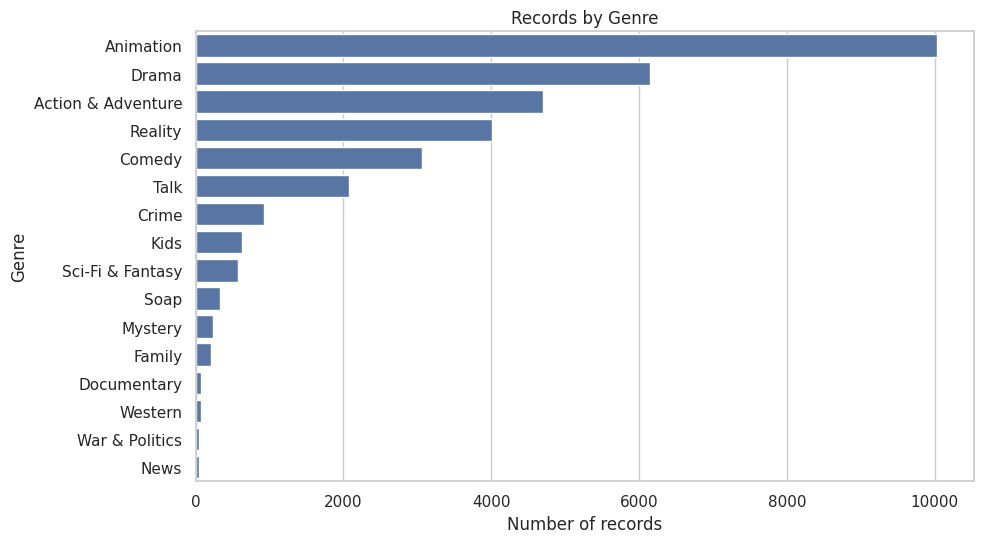


Platform distribution


,record_count
platform,
Netflix,12270
Hulu,7967
Prime Video,2693
Disney+,2467
Kocowa Amazon Channel,2245
OnDemandKorea,1582
Rakuten Viki,911
Peacock Premium,686
fuboTV,550


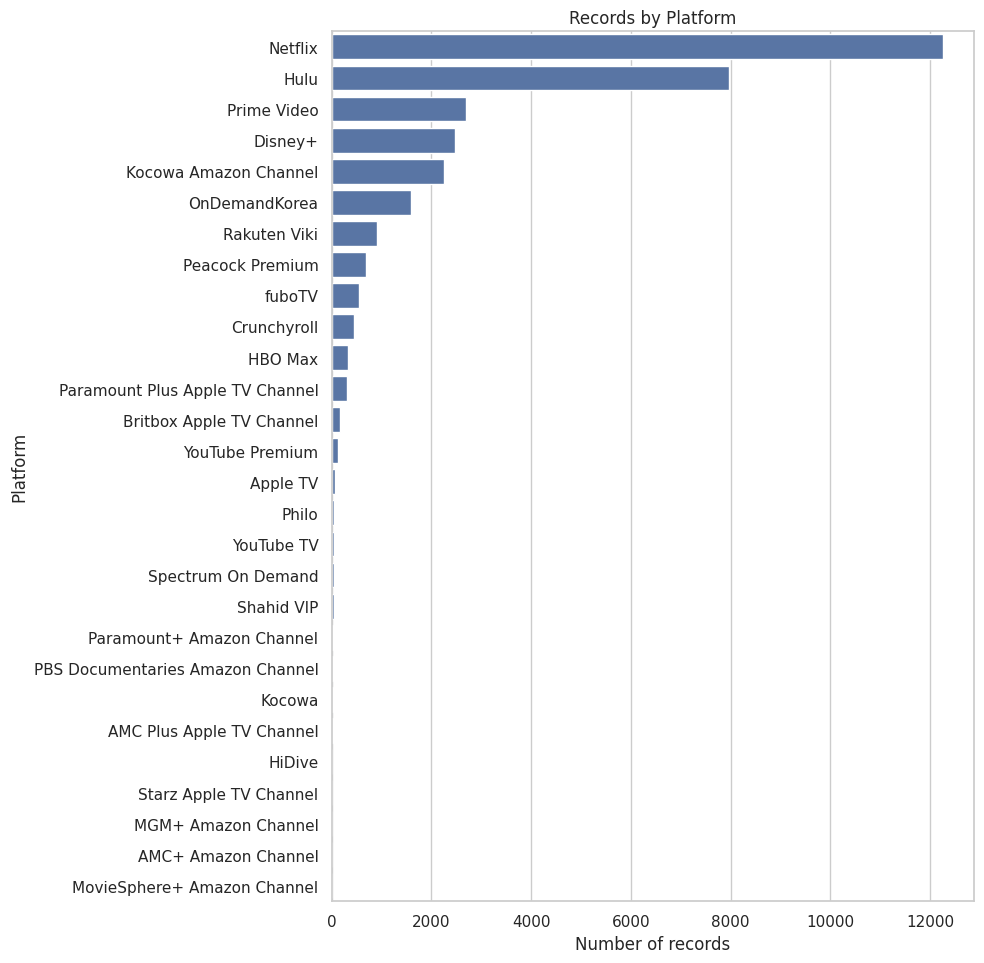


Attention Required distribution


,record_count
attention_required,
high,16878
medium,16293


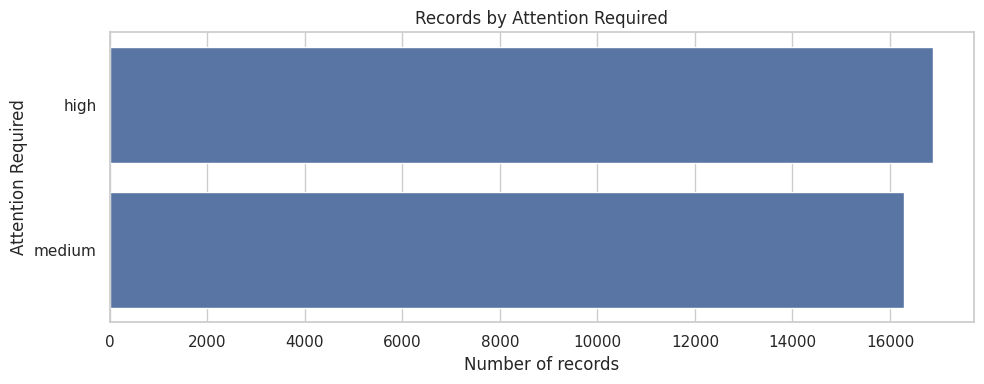


Retention Risk distribution


,record_count
retention_risk,
medium,27402
high,4804
low,965


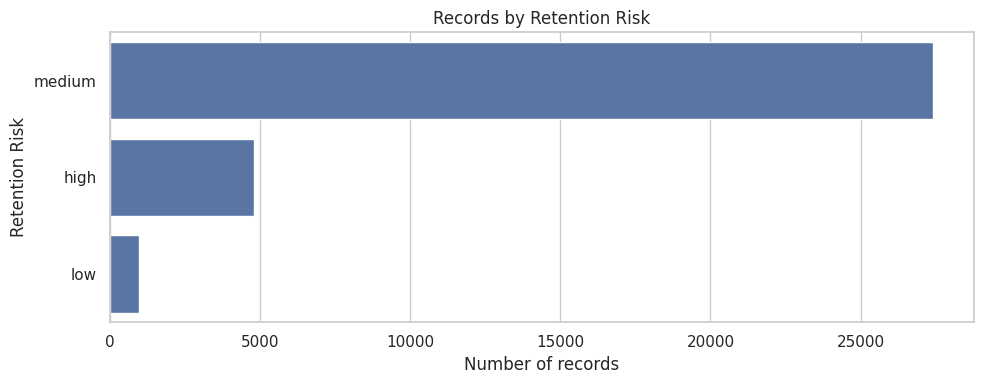

In [ ]:
# Look at the categorical variables named in the brief.
categorical_targets = [c for c in ["genre", "platform", "attention_required", "retention_risk"] if c in df.columns]

for col in categorical_targets:
    counts = df[col].value_counts(dropna=False)
    print(f"\n{col.replace('_', ' ').title()} distribution")
    display(counts.rename("record_count").to_frame())
    plt.figure(figsize=(10, max(4, 0.35 * len(counts))))
    sns.barplot(x=counts.values, y=counts.index)
    plt.title(f"Records by {col.replace('_', ' ').title()}")
    plt.xlabel("Number of records")
    plt.ylabel(col.replace("_", " ").title())
    plt.tight_layout()
    plt.show()

# Numerical Distribution Analysis


,count,mean,std,min,25%,50%,75%,max
episode_duration_min,33171.00,37.66,22.90,1.00,24.00,33.00,49.00,1225.00
avg_watch_percentage,33171.00,56.81,12.58,13.00,48.00,57.00,66.00,100.00
pause_count,33171.00,3.10,1.87,0.00,2.00,3.00,4.00,10.00
rewind_count,33171.00,2.00,1.55,0.00,1.00,2.00,3.00,8.00
hook_strength,33171.00,5.53,1.73,3.00,4.00,6.00,7.00,10.00
pacing_score,33171.00,5.40,1.23,3.00,4.00,5.00,6.00,8.00
cognitive_load,33171.00,6.20,1.32,4.00,5.00,7.00,7.00,9.00
drop_off_probability,33171.00,0.48,0.11,0.12,0.40,0.47,0.55,0.83


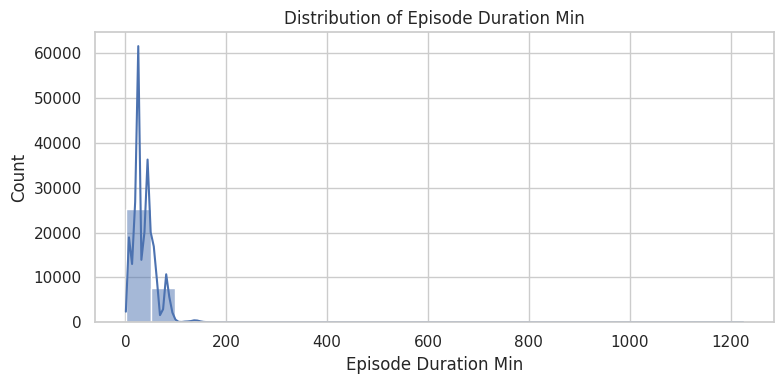

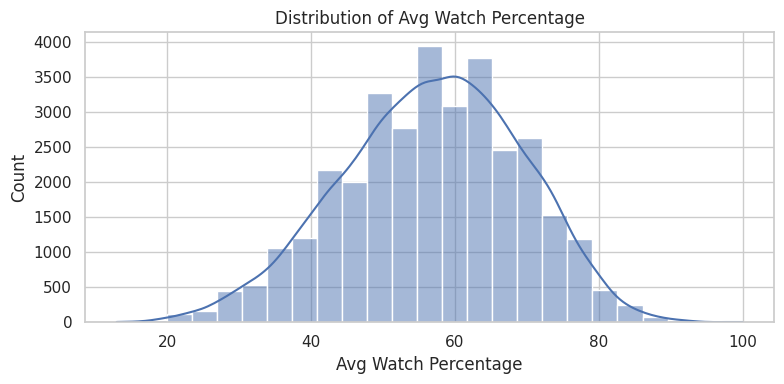

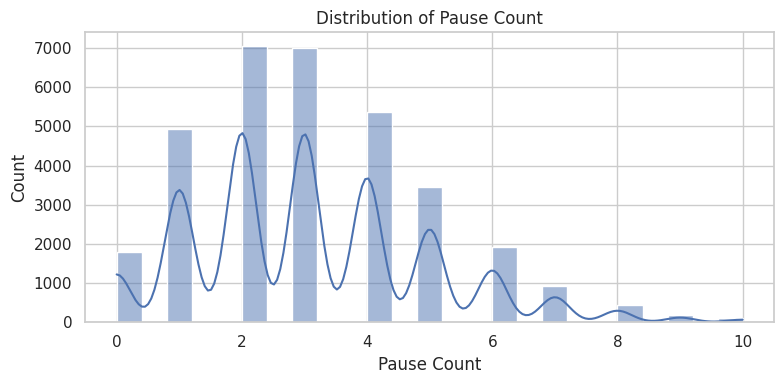

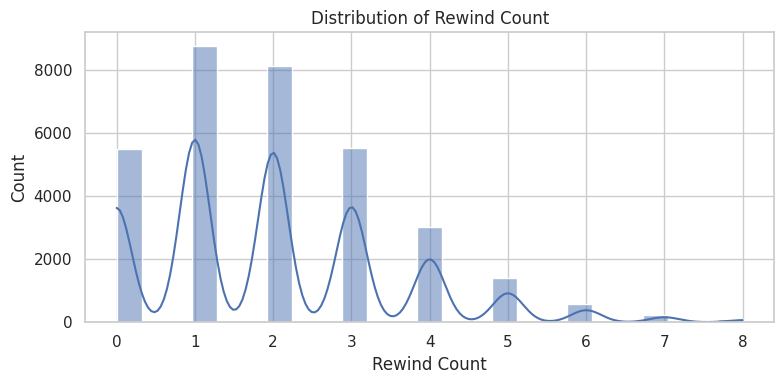

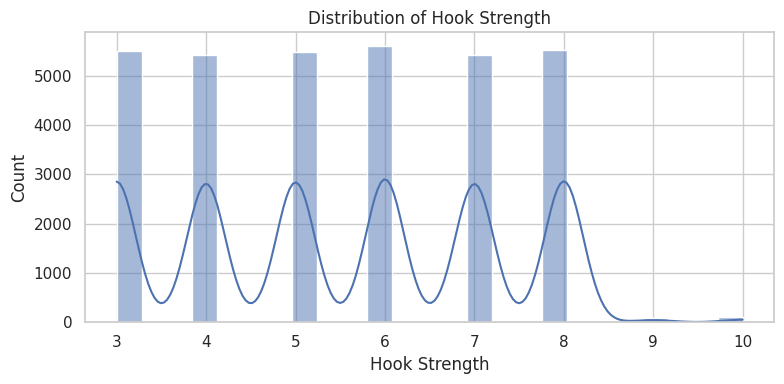

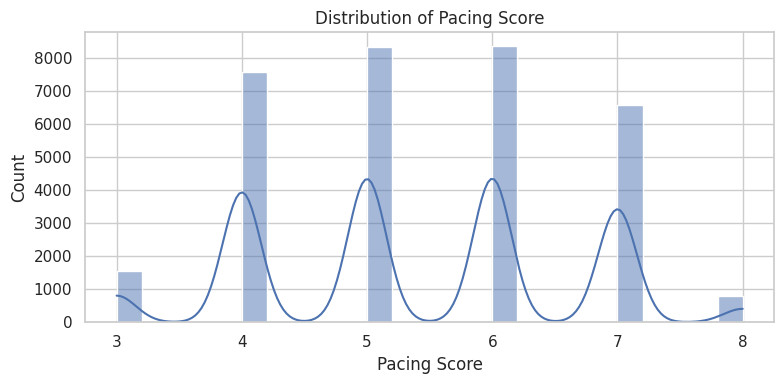

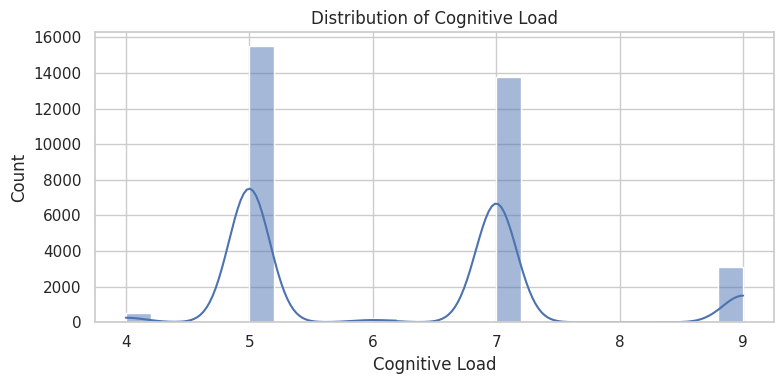

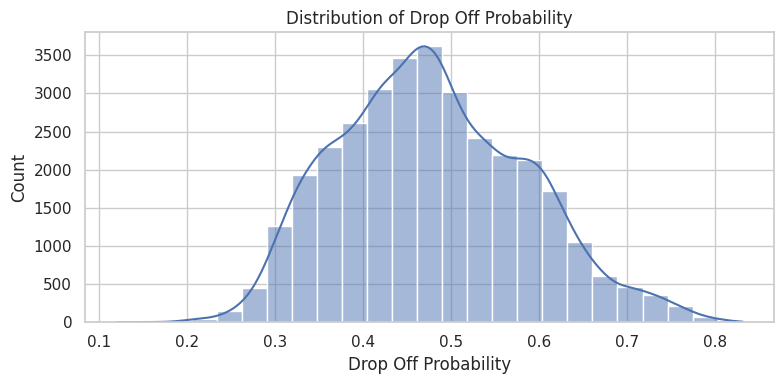

In [ ]:
distribution_cols = [
    c for c in [
        "episode_duration_min", "avg_watch_percentage", "pause_count",
        "rewind_count", "hook_strength", "pacing_score",
        "cognitive_load", "drop_off_probability"
    ] if c in df.columns
]

if distribution_cols:
    display(df[distribution_cols].describe().T)
    for col in distribution_cols:
        plt.figure(figsize=(8, 4))
        sns.histplot(data=df, x=col, bins=25, kde=True)
        plt.title(f"Distribution of {col.replace('_', ' ').title()}")
        plt.xlabel(col.replace("_", " ").title())
        plt.tight_layout()
        plt.show()

# Engagement Analysis


In [ ]:
# Formula supplied in the project brief. This is a project-defined index,
# not an official industry metric.
engagement_inputs = [
    "avg_watch_percentage", "hook_strength", "pacing_score", "visual_intensity"
]
if all(c in df.columns for c in engagement_inputs):
    df["engagement_score"] = (
        df["avg_watch_percentage"]
        + df["hook_strength"] * 5
        + df["pacing_score"] * 5
        + df["visual_intensity"] * 5
    ) / 2

    print("Engagement score summary:")
    display(df["engagement_score"].describe().to_frame())

    detail_cols = [c for c in ["title", "platform", "genre", "season_number", "episode_number",
                               "avg_watch_percentage", "engagement_score"] if c in df.columns]
    print("Highest engagement records:")
    display(df.nlargest(10, "engagement_score")[detail_cols])
else:
    print("Engagement score not calculated because one or more required fields are missing.")

Engagement score summary:


,engagement_score
count,33171.00
mean,70.73
std,12.02
min,30.00
25%,62.50
50%,71.00
75%,79.50
max,117.50


Highest engagement records:


,title,platform,genre,season_number,episode_number,avg_watch_percentage,engagement_score
16149,30 Rock,Prime Video,Comedy,1,1,100,117.50
1840,Young Sheldon,Netflix,Comedy,1,1,99,114.50
13312,Buffy the Vampire Slayer,Hulu,Sci-Fi & Fantasy,1,1,98,111.50
7315,The Late Show with Stephen Colbert,fuboTV,Comedy,1,12,94,109.50
1408,Tagesschau,Hulu,News,1,1,86,108.00
1198,Arrow,Netflix,Crime,1,1,85,107.50
27533,Good Mythical Morning,YouTube Premium,Comedy,1,50,89,107.00
33099,The Cosby Show,Philo,Comedy,1,6,89,107.00
197,Law & Order,Hulu,Crime,1,1,98,106.50
2342,Running Man,Rakuten Viki,Comedy,1,244,88,106.50


,record_count,average_engagement,average_watch_percentage
genre,,,
Comedy,3067,77.38,64.29
News,46,74.55,61.83
Documentary,75,72.59,57.25
Crime,926,71.69,57.22
Family,208,71.51,56.71
Sci-Fi & Fantasy,574,71.23,57.43
Soap,334,71.22,57.23
Animation,10028,71.08,57.11
Kids,632,71.07,56.65


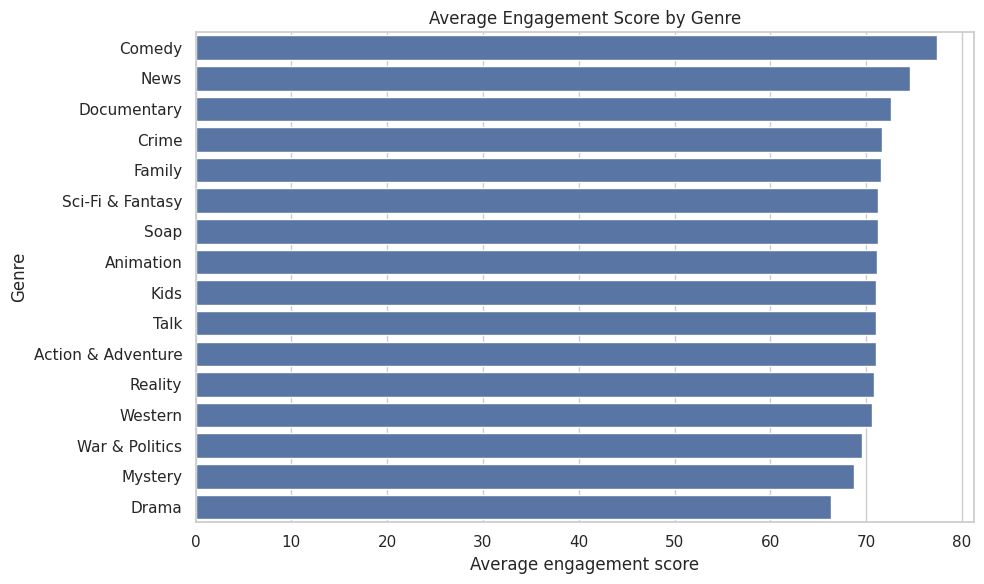

In [ ]:
if "engagement_score" in df and "genre" in df:
    genre_engagement = (
        df.groupby("genre", dropna=False)
        .agg(
            record_count=("engagement_score", "size"),
            average_engagement=("engagement_score", "mean"),
            average_watch_percentage=("avg_watch_percentage", "mean")
        )
        .sort_values("average_engagement", ascending=False)
    )
    display(genre_engagement.round(2))
    plt.figure(figsize=(10, 6))
    sns.barplot(data=genre_engagement.reset_index(), x="average_engagement", y="genre")
    plt.title("Average Engagement Score by Genre")
    plt.xlabel("Average engagement score")
    plt.ylabel("Genre")
    plt.tight_layout()
    plt.show()

# Watch Percentage Analysis by Genre


,record_count,average_watch_percentage,median_watch_percentage
genre,,,
Comedy,3067,64.29,64.00
News,46,61.83,61.50
Sci-Fi & Fantasy,574,57.43,58.00
Documentary,75,57.25,60.00
Soap,334,57.23,57.50
Talk,2074,57.23,58.00
Crime,926,57.22,58.00
Animation,10028,57.11,58.00
Action & Adventure,4705,57.11,58.00


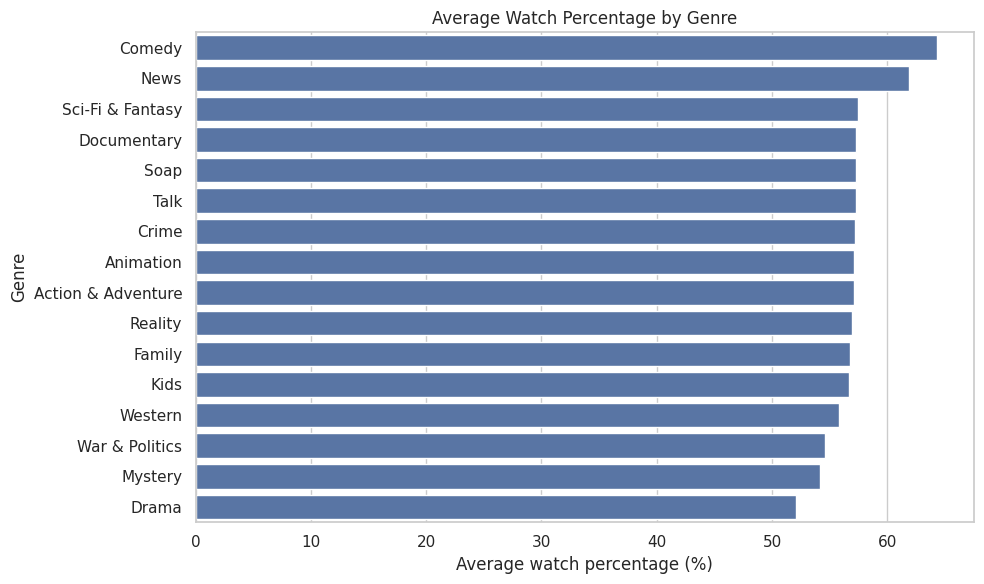

In [ ]:
if {"genre", "avg_watch_percentage"}.issubset(df.columns):
    genre_watch = (
        df.groupby("genre", dropna=False)
        .agg(
            record_count=("avg_watch_percentage", "size"),
            average_watch_percentage=("avg_watch_percentage", "mean"),
            median_watch_percentage=("avg_watch_percentage", "median")
        )
        .sort_values("average_watch_percentage", ascending=False)
    )
    display(genre_watch.round(2))
    plt.figure(figsize=(10, 6))
    sns.barplot(data=genre_watch.reset_index(), x="average_watch_percentage", y="genre")
    plt.title("Average Watch Percentage by Genre")
    plt.xlabel("Average watch percentage (%)")
    plt.ylabel("Genre")
    plt.tight_layout()
    plt.show()

# Episode Drop-Off Analysis


,record_count,drop_off_count,drop_off_rate,drop_off_rate_pct
genre,,,,
Drama,6142,1486,0.24,24.19
Mystery,233,44,0.19,18.88
Western,71,13,0.18,18.31
Documentary,75,13,0.17,17.33
Crime,926,147,0.16,15.88
War & Politics,51,8,0.16,15.69
Reality,4005,543,0.14,13.56
Animation,10028,1352,0.14,13.48
Soap,334,44,0.13,13.17


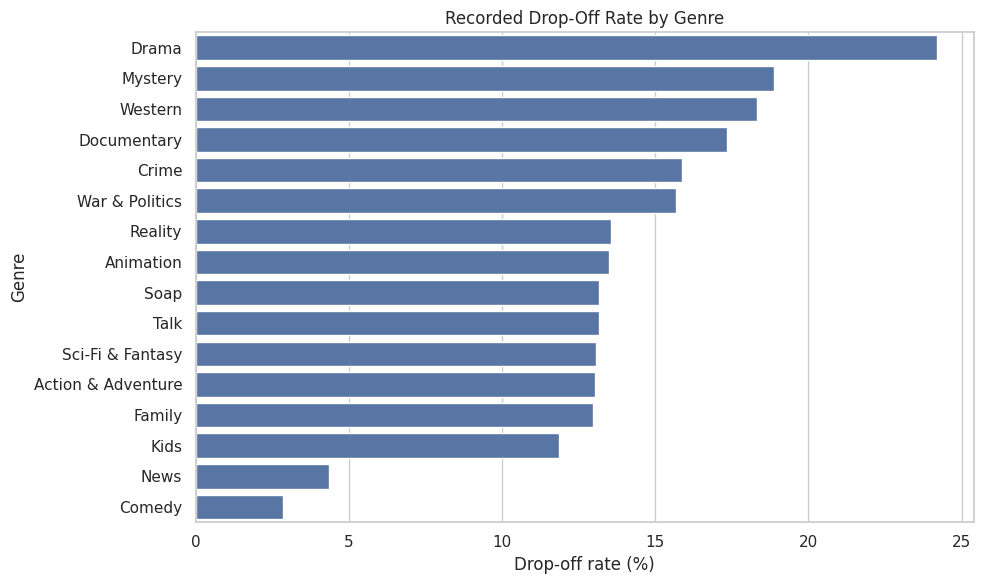

,episode_number,record_count,drop_off_count,drop_off_rate,average_watch_percentage,drop_off_rate_pct
0,1,500,18,0.04,64.94,3.60
1,2,497,89,0.18,56.31,17.91
2,3,492,69,0.14,56.34,14.02
3,4,487,79,0.16,56.41,16.22
4,5,484,75,0.15,55.72,15.50
...,...,...,...,...,...,...
2645,2646,1,0,0.00,71.00,0.00
2646,2647,1,0,0.00,50.00,0.00
2647,2648,1,0,0.00,80.00,0.00
2648,2649,1,0,0.00,58.00,0.00


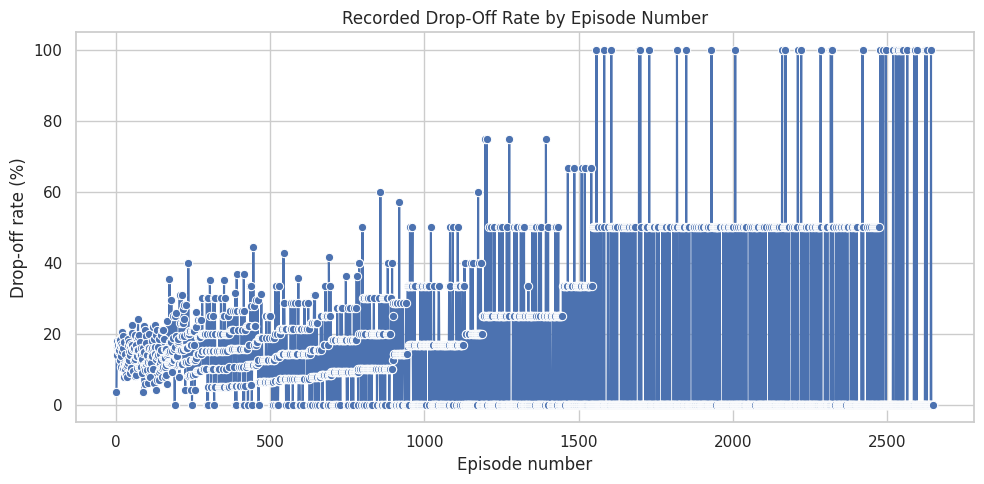

In [ ]:
if {"genre", "drop_off"}.issubset(df.columns):
    genre_dropoff = (
        df.groupby("genre", dropna=False)
        .agg(
            record_count=("drop_off", "size"),
            drop_off_count=("drop_off", "sum"),
            drop_off_rate=("drop_off", "mean")
        )
        .sort_values("drop_off_rate", ascending=False)
    )
    genre_dropoff["drop_off_rate_pct"] = genre_dropoff["drop_off_rate"] * 100
    display(genre_dropoff.round(3))
    plt.figure(figsize=(10, 6))
    sns.barplot(data=genre_dropoff.reset_index(), x="drop_off_rate_pct", y="genre")
    plt.title("Recorded Drop-Off Rate by Genre")
    plt.xlabel("Drop-off rate (%)")
    plt.ylabel("Genre")
    plt.tight_layout()
    plt.show()

if {"episode_number", "drop_off"}.issubset(df.columns):
    episode_dropoff = (
        df.groupby("episode_number", dropna=False)
        .agg(
            record_count=("drop_off", "size"),
            drop_off_count=("drop_off", "sum"),
            drop_off_rate=("drop_off", "mean"),
            average_watch_percentage=("avg_watch_percentage", "mean")
        )
        .reset_index()
        .sort_values("episode_number")
    )
    episode_dropoff["drop_off_rate_pct"] = episode_dropoff["drop_off_rate"] * 100
    display(episode_dropoff.round(3))
    plt.figure(figsize=(10, 5))
    sns.lineplot(data=episode_dropoff, x="episode_number", y="drop_off_rate_pct", marker="o")
    plt.title("Recorded Drop-Off Rate by Episode Number")
    plt.xlabel("Episode number")
    plt.ylabel("Drop-off rate (%)")
    plt.tight_layout()
    plt.show()

# Retention Risk Analysis


,record_count,average_avg_watch_percentage,average_drop_off_probability,average_cognitive_load,average_hook_strength,average_pacing_score,average_drop_off
retention_risk,,,,,,,
high,4804,37.08,0.66,8.03,4.25,4.16,1.00
low,965,81.17,0.28,4.77,7.83,6.67,0.00
medium,27402,59.41,0.46,5.92,5.67,5.57,0.00


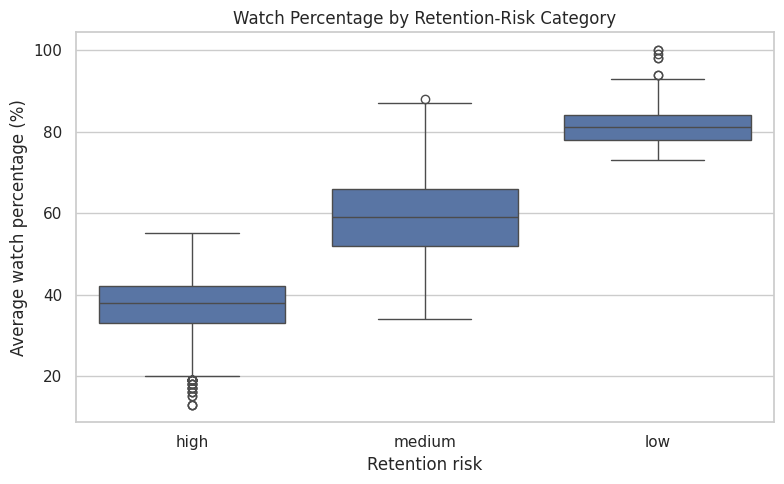

Records labelled high risk: 4,804
Share labelled high risk: 14.48%


,title,platform,genre,season_number,episode_number,avg_watch_percentage,drop_off_probability,retention_risk
20822,Blood Flowers,Hulu,Drama,1,42,21,0.83,high
6280,Doraemon,Hulu,Action & Adventure,1,1259,18,0.82,high
21860,Pleasant Goat and Big Big Wolf,Netflix,Animation,1,510,23,0.82,high
15252,A Kindred Spirit,Hulu,Drama,1,1113,21,0.82,high
31170,Show! Music Core,Kocowa Amazon Channel,Reality,1,762,24,0.82,high
14403,A Kindred Spirit,Hulu,Drama,1,264,20,0.81,high
31394,Station 19,Hulu,Drama,1,5,16,0.81,high
25255,This Is Us,Disney+,Drama,1,6,23,0.81,high
32169,CID,Netflix,Action & Adventure,1,623,19,0.81,high
10680,Sazae-san,Netflix,Animation,1,2160,15,0.81,high


In [ ]:
if "retention_risk" in df.columns:
    risk_cols = [c for c in [
        "avg_watch_percentage", "drop_off_probability", "cognitive_load",
        "hook_strength", "pacing_score", "drop_off"
    ] if c in df.columns]
    risk_summary = df.groupby("retention_risk", dropna=False).agg(
        record_count=("retention_risk", "size"),
        **{f"average_{c}": (c, "mean") for c in risk_cols}
    )
    display(risk_summary.round(3))

    if "avg_watch_percentage" in df:
        plt.figure(figsize=(8, 5))
        sns.boxplot(data=df, x="retention_risk", y="avg_watch_percentage")
        plt.title("Watch Percentage by Retention-Risk Category")
        plt.xlabel("Retention risk")
        plt.ylabel("Average watch percentage (%)")
        plt.tight_layout()
        plt.show()

    high_mask = df["retention_risk"].astype(str).str.lower().eq("high")
    print(f"Records labelled high risk: {int(high_mask.sum()):,}")
    print(f"Share labelled high risk: {high_mask.mean() * 100:.2f}%")
    review_cols = [c for c in [
        "title", "platform", "genre", "season_number", "episode_number",
        "avg_watch_percentage", "drop_off_probability", "retention_risk"
    ] if c in df.columns]
    if "drop_off_probability" in df.columns:
        display(df.loc[high_mask].sort_values("drop_off_probability", ascending=False)[review_cols].head(20))

# Engagement vs Drop-Off


,record_count,average_watch_percentage,median_watch_percentage
drop_off,,,
0,28367,60.15,60.00
1,4804,37.08,38.00


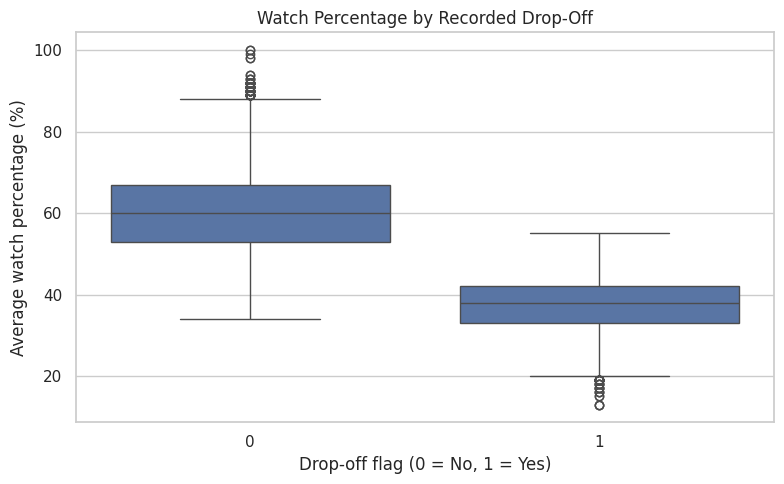

Correlation between drop-off probability and watch percentage: -0.957


In [ ]:
if {"drop_off", "avg_watch_percentage"}.issubset(df.columns):
    display(
        df.groupby("drop_off")
        .agg(
            record_count=("avg_watch_percentage", "size"),
            average_watch_percentage=("avg_watch_percentage", "mean"),
            median_watch_percentage=("avg_watch_percentage", "median")
        ).round(2)
    )
    plt.figure(figsize=(8, 5))
    sns.boxplot(data=df, x="drop_off", y="avg_watch_percentage")
    plt.title("Watch Percentage by Recorded Drop-Off")
    plt.xlabel("Drop-off flag (0 = No, 1 = Yes)")
    plt.ylabel("Average watch percentage (%)")
    plt.tight_layout()
    plt.show()

if {"drop_off_probability", "avg_watch_percentage"}.issubset(df.columns):
    corr = df["drop_off_probability"].corr(df["avg_watch_percentage"])
    print(f"Correlation between drop-off probability and watch percentage: {corr:.3f}")

# Hook Strength vs Viewer Engagement


,hook_strength,record_count,average_watch_percentage
0,3,5515,46.66
1,4,5430,50.80
2,5,5484,54.57
3,6,5606,58.66
4,7,5423,62.74
5,8,5527,66.83
6,9,83,70.40
7,10,103,73.54


Correlation: 0.552


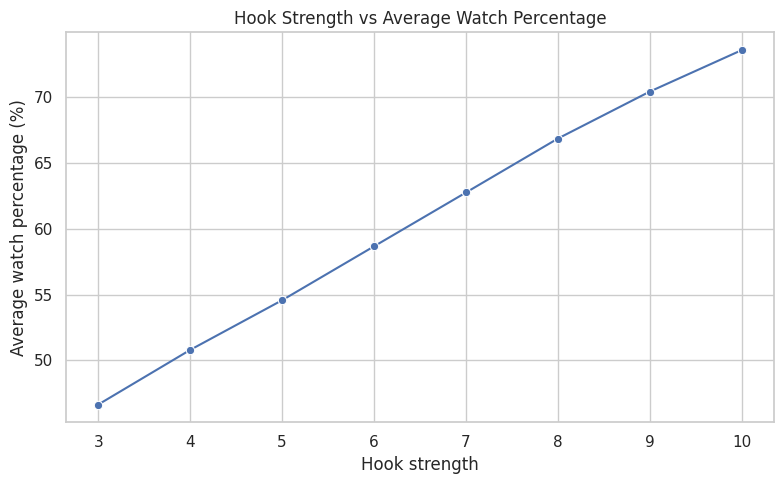

In [ ]:
if {"hook_strength", "avg_watch_percentage"}.issubset(df.columns):
    hook_summary = df.groupby("hook_strength").agg(
        record_count=("avg_watch_percentage", "size"),
        average_watch_percentage=("avg_watch_percentage", "mean")
    ).reset_index()
    display(hook_summary.round(2))
    print("Correlation:", round(df["hook_strength"].corr(df["avg_watch_percentage"]), 3))
    plt.figure(figsize=(8, 5))
    sns.lineplot(data=hook_summary, x="hook_strength", y="average_watch_percentage", marker="o")
    plt.title("Hook Strength vs Average Watch Percentage")
    plt.xlabel("Hook strength")
    plt.ylabel("Average watch percentage (%)")
    plt.tight_layout()
    plt.show()

# Pacing vs Watch Percentage


,pacing_score,record_count,average_watch_percentage
0,3,1550,42.24
1,4,7562,45.15
2,5,8340,58.25
3,6,8358,61.39
4,7,6580,64.10
5,8,781,72.63


Correlation: 0.594


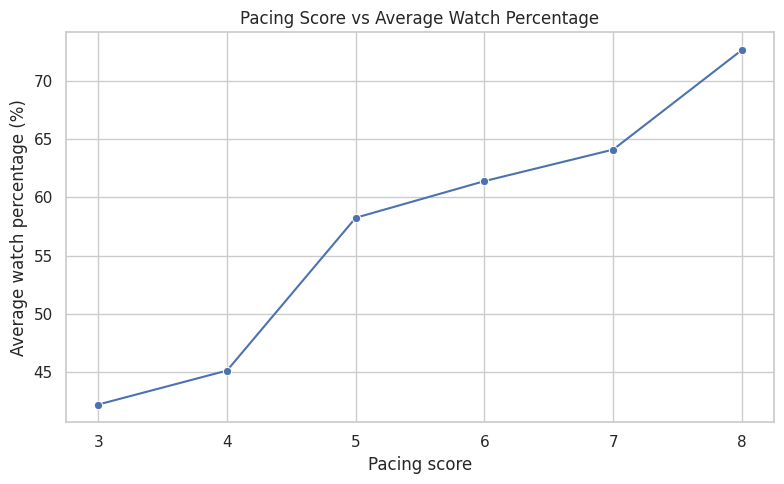

In [ ]:
if {"pacing_score", "avg_watch_percentage"}.issubset(df.columns):
    pacing_summary = df.groupby("pacing_score").agg(
        record_count=("avg_watch_percentage", "size"),
        average_watch_percentage=("avg_watch_percentage", "mean")
    ).reset_index()
    display(pacing_summary.round(2))
    print("Correlation:", round(df["pacing_score"].corr(df["avg_watch_percentage"]), 3))
    plt.figure(figsize=(8, 5))
    sns.lineplot(data=pacing_summary, x="pacing_score", y="average_watch_percentage", marker="o")
    plt.title("Pacing Score vs Average Watch Percentage")
    plt.xlabel("Pacing score")
    plt.ylabel("Average watch percentage (%)")
    plt.tight_layout()
    plt.show()

# Cognitive Load Analysis


,cognitive_load,record_count,average_watch_percentage,average_drop_off_probability
0,4,527,75.74,0.32
1,5,15512,64.34,0.40
2,6,254,66.19,0.43
3,7,13783,51.63,0.53
4,9,3095,38.10,0.66


Cognitive load vs watch percentage correlation: -0.692


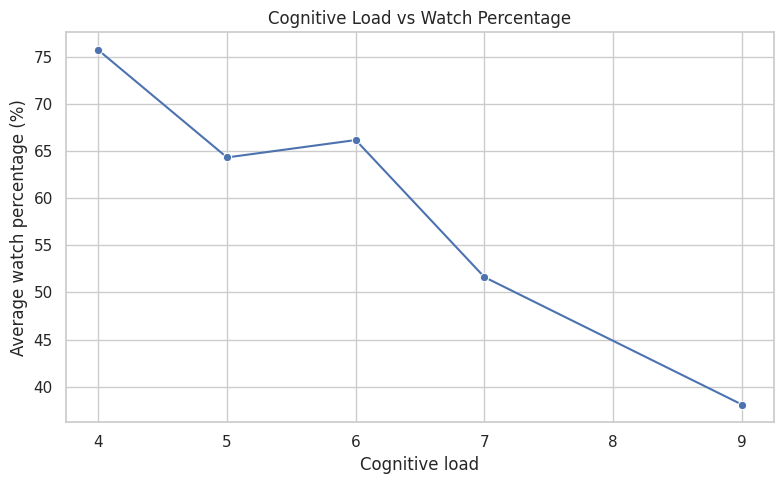

In [ ]:
if {"cognitive_load", "avg_watch_percentage"}.issubset(df.columns):
    cognitive_summary = df.groupby("cognitive_load").agg(
        record_count=("avg_watch_percentage", "size"),
        average_watch_percentage=("avg_watch_percentage", "mean")
    ).reset_index()
    if "drop_off_probability" in df:
        extra = df.groupby("cognitive_load")["drop_off_probability"].mean().rename("average_drop_off_probability")
        cognitive_summary = cognitive_summary.merge(extra, on="cognitive_load", how="left")
    display(cognitive_summary.round(3))
    print("Cognitive load vs watch percentage correlation:",
          round(df["cognitive_load"].corr(df["avg_watch_percentage"]), 3))
    plt.figure(figsize=(8, 5))
    sns.lineplot(data=cognitive_summary, x="cognitive_load", y="average_watch_percentage", marker="o")
    plt.title("Cognitive Load vs Watch Percentage")
    plt.xlabel("Cognitive load")
    plt.ylabel("Average watch percentage (%)")
    plt.tight_layout()
    plt.show()

# Pause & Rewind Analysis


pause_count vs watch percentage correlation: -0.235


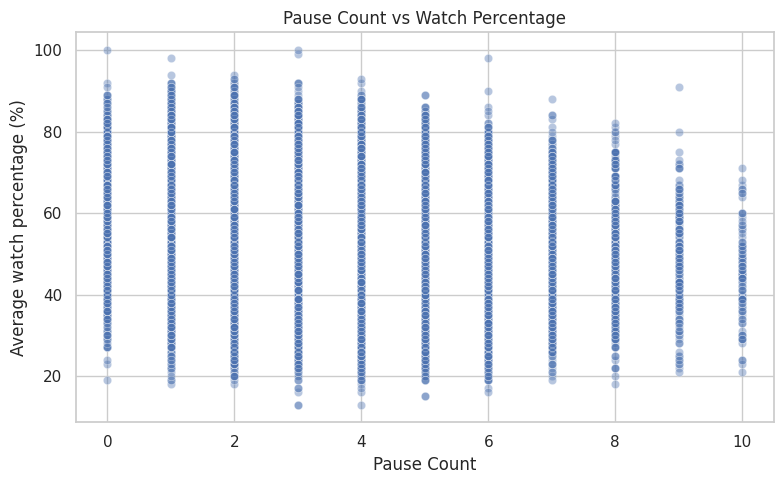

rewind_count vs watch percentage correlation: -0.011


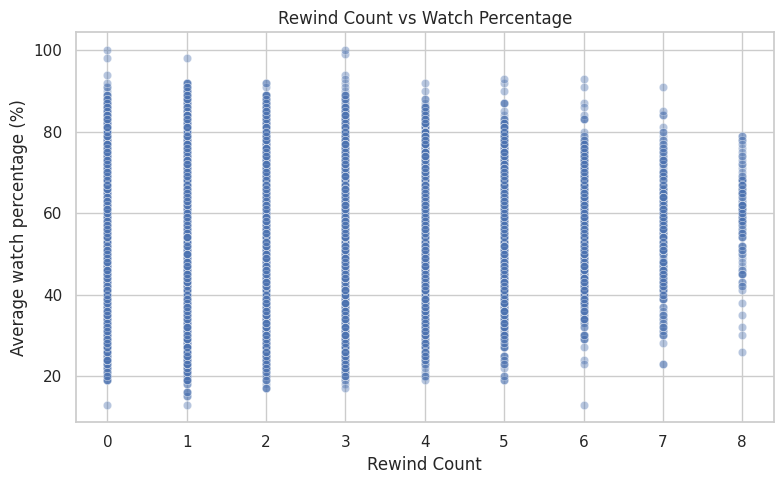

,record_count,intro_skip_rate,intro_skip_rate_pct
genre,,,
War & Politics,51,0.53,52.94
Mystery,233,0.53,52.79
Documentary,75,0.51,50.67
Reality,4005,0.51,50.66
Animation,10028,0.50,50.31
Soap,334,0.50,50.30
Talk,2074,0.50,50.10
Action & Adventure,4705,0.50,49.63
Sci-Fi & Fantasy,574,0.49,48.95


In [ ]:
for col in ["pause_count", "rewind_count"]:
    if {col, "avg_watch_percentage"}.issubset(df.columns):
        print(f"{col} vs watch percentage correlation: {df[col].corr(df['avg_watch_percentage']):.3f}")
        plt.figure(figsize=(8, 5))
        sns.scatterplot(data=df, x=col, y="avg_watch_percentage", alpha=0.4)
        plt.title(f"{col.replace('_', ' ').title()} vs Watch Percentage")
        plt.xlabel(col.replace("_", " ").title())
        plt.ylabel("Average watch percentage (%)")
        plt.tight_layout()
        plt.show()

if {"genre", "skip_intro"}.issubset(df.columns):
    intro_summary = df.groupby("genre").agg(
        record_count=("skip_intro", "size"),
        intro_skip_rate=("skip_intro", "mean")
    ).sort_values("intro_skip_rate", ascending=False)
    intro_summary["intro_skip_rate_pct"] = intro_summary["intro_skip_rate"] * 100
    display(intro_summary.round(2))

# Season-Level Analysis


In [ ]:
if {"season_number", "engagement_score"}.issubset(df.columns):
    season_summary = df.groupby("season_number").agg(
        record_count=("engagement_score", "size"),
        average_engagement=("engagement_score", "mean"),
        average_watch_percentage=("avg_watch_percentage", "mean"),
        recorded_drop_off_rate=("drop_off", "mean") if "drop_off" in df.columns else ("engagement_score", "size")
    ).sort_values("average_engagement", ascending=False)
    display(season_summary.round(3))
    if df["season_number"].nunique() == 1:
        print("Only one season number is present, so a season-to-season comparison is not possible.")
else:
    print("Season engagement could not be calculated because required columns are missing.")

,record_count,average_engagement,average_watch_percentage,recorded_drop_off_rate
season_number,,,,
1,33171,70.73,56.81,0.14


Only one season number is present, so a season-to-season comparison is not possible.


# Top & Bottom Performing Episodes


In [ ]:
detail_cols = [c for c in [
    "title", "platform", "genre", "season_number", "episode_number",
    "episode_duration_min", "avg_watch_percentage", "engagement_score",
    "drop_off_probability", "retention_risk"
] if c in df.columns]

if "engagement_score" in df:
    print("Top 10 episodes by engagement score")
    display(df.nlargest(10, "engagement_score")[detail_cols].reset_index(drop=True))
    print("Bottom 10 episodes by engagement score")
    display(df.nsmallest(10, "engagement_score")[detail_cols].reset_index(drop=True))

if "avg_watch_percentage" in df:
    print("Top 10 episodes by watch percentage")
    display(df.nlargest(10, "avg_watch_percentage")[detail_cols].reset_index(drop=True))

if "drop_off_probability" in df:
    print("Top 10 episodes by drop-off probability")
    display(df.nlargest(10, "drop_off_probability")[detail_cols].reset_index(drop=True))

Top 10 episodes by engagement score


,title,platform,genre,season_number,episode_number,episode_duration_min,avg_watch_percentage,engagement_score,drop_off_probability,retention_risk
0,30 Rock,Prime Video,Comedy,1,1,22,100,117.50,0.12,low
1,Young Sheldon,Netflix,Comedy,1,1,21,99,114.50,0.15,low
2,Buffy the Vampire Slayer,Hulu,Sci-Fi & Fantasy,1,1,42,98,111.50,0.17,low
3,The Late Show with Stephen Colbert,fuboTV,Comedy,1,12,45,94,109.50,0.19,low
4,Tagesschau,Hulu,News,1,1,15,86,108.00,0.24,low
5,Arrow,Netflix,Crime,1,1,43,85,107.50,0.24,low
6,Good Mythical Morning,YouTube Premium,Comedy,1,50,10,89,107.00,0.22,low
7,The Cosby Show,Philo,Comedy,1,6,22,89,107.00,0.21,low
8,Law & Order,Hulu,Crime,1,1,48,98,106.50,0.22,low
9,Running Man,Rakuten Viki,Comedy,1,244,85,88,106.50,0.24,low


Bottom 10 episodes by engagement score


,title,platform,genre,season_number,episode_number,episode_duration_min,avg_watch_percentage,engagement_score,drop_off_probability,retention_risk
0,Dreams of Liberty,Hulu,Drama,1,274,35,15,30.00,0.81,high
1,A Kindred Spirit,Hulu,Drama,1,575,22,13,31.50,0.81,high
2,6 of Us,Netflix,Drama,1,4,141,20,32.50,0.77,high
3,Ghum Hai Kisikey Pyaar Meiin,Hulu,Drama,1,73,22,20,32.50,0.76,high
4,The Closer,Peacock Premium,Crime,1,6,46,17,33.50,0.79,high
5,AIBOU: Tokyo Detective Duo,Hulu,Drama,1,10,54,23,34.00,0.74,high
6,Dreams of Liberty,Hulu,Drama,1,64,51,13,34.00,0.80,high
7,Ghum Hai Kisikey Pyaar Meiin,Hulu,Drama,1,558,60,23,34.00,0.74,high
8,Grimm,Prime Video,Drama,1,7,41,19,34.50,0.79,high
9,A Kindred Spirit,Hulu,Drama,1,517,22,24,34.50,0.74,high


Top 10 episodes by watch percentage


,title,platform,genre,season_number,episode_number,episode_duration_min,avg_watch_percentage,engagement_score,drop_off_probability,retention_risk
0,30 Rock,Prime Video,Comedy,1,1,22,100,117.50,0.12,low
1,2 Broke Girls,Netflix,Comedy,1,1,22,100,100.00,0.17,low
2,Young Sheldon,Netflix,Comedy,1,1,21,99,114.50,0.15,low
3,Law & Order,Hulu,Crime,1,1,48,98,106.50,0.22,low
4,Buffy the Vampire Slayer,Hulu,Sci-Fi & Fantasy,1,1,42,98,111.50,0.17,low
5,Ninja Boy Rantaro,Hulu,Comedy,1,45,30,94,102.00,0.20,low
6,The Late Show with Stephen Colbert,fuboTV,Comedy,1,12,45,94,109.50,0.19,low
7,Running Man,Rakuten Viki,Comedy,1,392,85,93,104.00,0.22,low
8,Will & Grace,Hulu,Comedy,1,10,22,93,104.00,0.20,low
9,CID,Netflix,Action & Adventure,1,1132,43,93,94.00,0.25,low


Top 10 episodes by drop-off probability


,title,platform,genre,season_number,episode_number,episode_duration_min,avg_watch_percentage,engagement_score,drop_off_probability,retention_risk
0,Blood Flowers,Hulu,Drama,1,42,65,21,38.00,0.83,high
1,Doraemon,Hulu,Action & Adventure,1,1259,38,18,36.50,0.82,high
2,Pleasant Goat and Big Big Wolf,Netflix,Animation,1,510,14,23,44.00,0.82,high
3,A Kindred Spirit,Hulu,Drama,1,1113,22,21,40.50,0.82,high
4,Show! Music Core,Kocowa Amazon Channel,Reality,1,762,48,24,37.00,0.82,high
5,A Kindred Spirit,Hulu,Drama,1,264,31,20,47.50,0.81,high
6,Station 19,Hulu,Drama,1,5,43,16,38.00,0.81,high
7,This Is Us,Disney+,Drama,1,6,43,23,39.00,0.81,high
8,CID,Netflix,Action & Adventure,1,623,40,19,44.50,0.81,high
9,Sazae-san,Netflix,Animation,1,2160,25,15,37.50,0.81,high


# Correlation Analysis


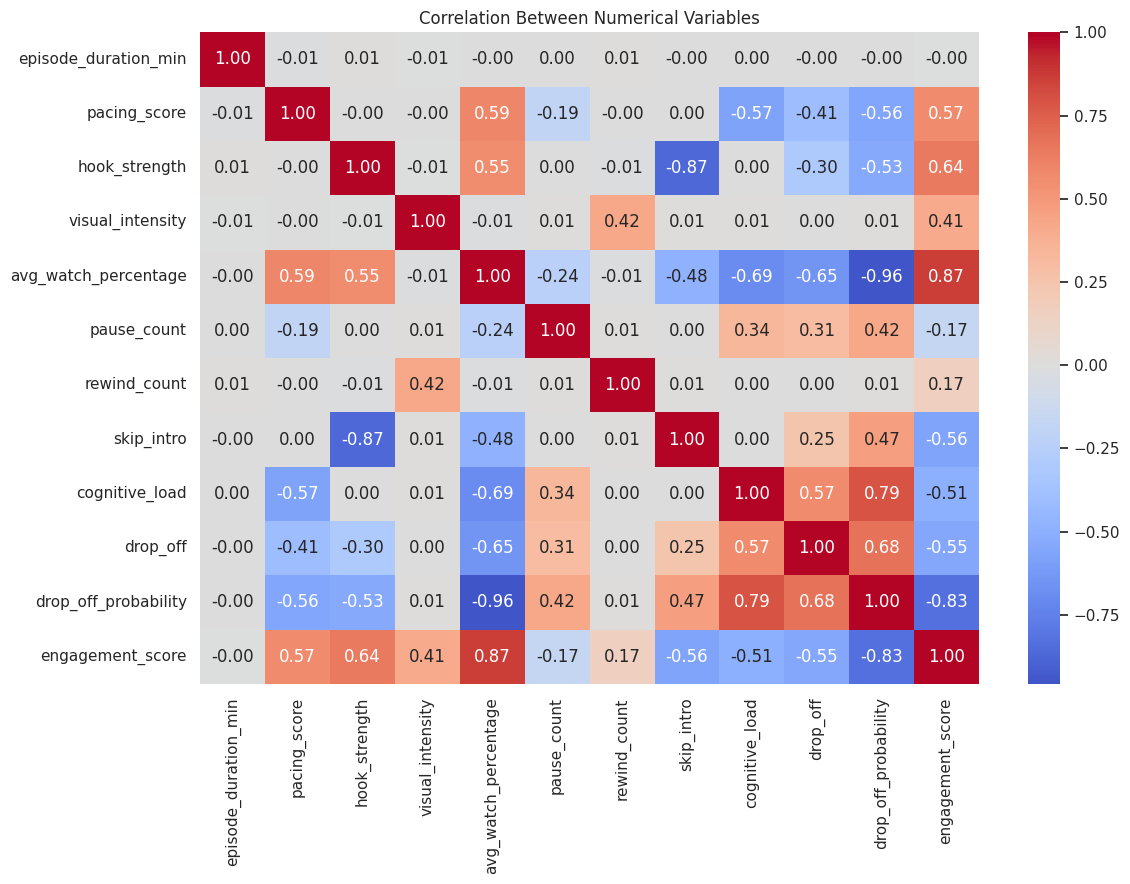

,episode_duration_min,pacing_score,hook_strength,visual_intensity,avg_watch_percentage,pause_count,rewind_count,skip_intro,cognitive_load,drop_off,drop_off_probability,engagement_score
episode_duration_min,1.00,-0.01,0.01,-0.01,-0.00,0.01,0.01,-0.00,0.00,-0.00,-0.00,-0.00
pacing_score,-0.01,1.00,-0.00,-0.00,0.59,-0.19,-0.00,0.00,-0.57,-0.41,-0.56,0.57
hook_strength,0.01,-0.00,1.00,-0.01,0.55,0.00,-0.01,-0.87,0.00,-0.30,-0.53,0.65
visual_intensity,-0.01,-0.00,-0.01,1.00,-0.01,0.01,0.42,0.01,0.01,0.00,0.01,0.41
avg_watch_percentage,-0.00,0.59,0.55,-0.01,1.00,-0.23,-0.01,-0.48,-0.69,-0.65,-0.96,0.87
pause_count,0.01,-0.19,0.00,0.01,-0.23,1.00,0.01,0.00,0.34,0.31,0.42,-0.17
rewind_count,0.01,-0.00,-0.01,0.42,-0.01,0.01,1.00,0.01,0.00,0.00,0.01,0.17
skip_intro,-0.00,0.00,-0.87,0.01,-0.48,0.00,0.01,1.00,0.00,0.25,0.47,-0.56
cognitive_load,0.00,-0.57,0.00,0.01,-0.69,0.34,0.00,0.00,1.00,0.57,0.79,-0.51
drop_off,-0.00,-0.41,-0.30,0.00,-0.65,0.31,0.00,0.25,0.57,1.00,0.68,-0.55


In [ ]:
correlation_candidates = [
    "episode_duration_min", "pacing_score", "hook_strength", "visual_intensity",
    "avg_watch_percentage", "pause_count", "rewind_count", "skip_intro",
    "cognitive_load", "drop_off", "drop_off_probability", "engagement_score"
]
correlation_cols = [c for c in correlation_candidates if c in df.columns and pd.api.types.is_numeric_dtype(df[c])]

if len(correlation_cols) >= 2:
    corr_matrix = df[correlation_cols].corr()
    plt.figure(figsize=(12, 9))
    sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0)
    plt.title("Correlation Between Numerical Variables")
    plt.tight_layout()
    plt.show()
    display(corr_matrix.round(3))
else:
    print("Not enough numerical columns are available for a correlation matrix.")

# Final Business Questions


In [ ]:
# Print data-backed summaries for the 20 questions in the project brief.
# These are descriptive findings from this synthetic dataset, not Hotstar results.

if "genre_engagement" in globals() and not genre_engagement.empty:
    print("1. Genre with highest average engagement:")
    display(genre_engagement.head(1))

if "genre_dropoff" in globals() and not genre_dropoff.empty:
    print("\n2. Genre with highest recorded drop-off rate:")
    display(genre_dropoff.head(1))

if "avg_watch_percentage" in df:
    print("\n3. Episodes with highest watch percentage:")
    display(df.nlargest(10, "avg_watch_percentage")[detail_cols].reset_index(drop=True))

if "drop_off_probability" in df:
    print("\n4. Episodes with highest drop-off probability:")
    display(df.nlargest(10, "drop_off_probability")[detail_cols].reset_index(drop=True))

for question, col in [
    ("5. Hook strength vs watch percentage", "hook_strength"),
    ("6. Pacing vs engagement/watch percentage", "pacing_score"),
    ("7. Cognitive load vs watch percentage", "cognitive_load"),
    ("8. Pauses vs watch percentage", "pause_count"),
    ("9. Rewinds vs watch percentage", "rewind_count"),
    ("13. Episode duration vs watch percentage", "episode_duration_min")
]:
    if col in df and "avg_watch_percentage" in df:
        print(f"\n{question}: correlation = {df[col].corr(df['avg_watch_percentage']):.3f}")

if "season_summary" in globals() and not season_summary.empty:
    print("\n10. Season with highest average engagement:")
    display(season_summary.head(1))

if "episode_dropoff" in globals() and not episode_dropoff.empty:
    print("\n11. Episode numbers with highest recorded drop-off rate:")
    display(episode_dropoff.sort_values("drop_off_rate", ascending=False).head(10))

if "intro_summary" in globals() and not intro_summary.empty:
    print("\n12. Intro skip rates by genre:")
    display(intro_summary.head(10))

if {"show_id", "title", "engagement_score"}.issubset(df.columns):
    print("\n14. Shows with consistently high engagement (at least 3 records):")
    show_summary = df.groupby(["show_id", "title"]).agg(
        record_count=("engagement_score", "size"),
        average_engagement=("engagement_score", "mean"),
        average_watch_percentage=("avg_watch_percentage", "mean")
    ).reset_index()
    display(show_summary[show_summary["record_count"] >= 3].sort_values("average_engagement", ascending=False).head(10))

if {"retention_risk", "title"}.issubset(df.columns):
    high_risk = df["retention_risk"].astype(str).str.lower().eq("high")
    print("\n15. Shows with the most high-risk records:")
    high_risk_shows = df.assign(high_risk=high_risk.astype(int)).groupby("title").agg(
        record_count=("title", "size"), high_risk_records=("high_risk", "sum")
    ).sort_values("high_risk_records", ascending=False)
    display(high_risk_shows.head(10))

    print("\n16. Percentage labelled high retention risk:")
    print(f"{high_risk.mean() * 100:.2f}%")

    feature_cols = [c for c in [
        "avg_watch_percentage", "hook_strength", "pacing_score", "visual_intensity",
        "cognitive_load", "pause_count", "rewind_count", "drop_off_probability"
    ] if c in df]
    print("\n17. Average characteristics of high-risk records:")
    display(df.loc[high_risk, feature_cols].mean().to_frame("high_risk_average"))

    if "engagement_score" in df:
        high_engagement = df["engagement_score"] >= df["engagement_score"].quantile(0.90)
        print("\n18. Average characteristics of top 10% engagement records:")
        display(df.loc[high_engagement, feature_cols].mean().to_frame("high_engagement_average"))

if "engagement_score" in df:
    print("\n19. Content to consider for promotion review (high engagement only):")
    display(df.sort_values("engagement_score", ascending=False)[detail_cols].head(15))

if "drop_off" in df:
    print("\n20. Episodes to investigate (recorded drop-off or high-risk label):")
    mask = df["drop_off"].eq(1)
    if "retention_risk" in df:
        mask = mask | df["retention_risk"].astype(str).str.lower().eq("high")
    sort_cols = [c for c in ["drop_off_probability", "avg_watch_percentage"] if c in df]
    ascending = [False, True][:len(sort_cols)]
    review = df.loc[mask]
    if sort_cols:
        review = review.sort_values(sort_cols, ascending=ascending)
    display(review[detail_cols].head(20))

1. Genre with highest average engagement:


,record_count,average_engagement,average_watch_percentage
genre,,,
Comedy,3067,77.38,64.29



2. Genre with highest recorded drop-off rate:


,record_count,drop_off_count,drop_off_rate,drop_off_rate_pct
genre,,,,
Drama,6142,1486,0.24,24.19



3. Episodes with highest watch percentage:


...

,high_engagement_average
avg_watch_percentage,74.42
hook_strength,7.44
pacing_score,6.51
visual_intensity,7.58
cognitive_load,5.27
pause_count,2.64
rewind_count,2.47
drop_off_probability,0.34



19. Content to consider for promotion review (high engagement only):


,title,platform,genre,season_number,episode_number,episode_duration_min,avg_watch_percentage,engagement_score,drop_off_probability,retention_risk
16149,30 Rock,Prime Video,Comedy,1,1,22,100,117.50,0.12,low
1840,Young Sheldon,Netflix,Comedy,1,1,21,99,114.50,0.15,low
13312,Buffy the Vampire Slayer,Hulu,Sci-Fi & Fantasy,1,1,42,98,111.50,0.17,low
7315,The Late Show with Stephen Colbert,fuboTV,Comedy,1,12,45,94,109.50,0.19,low
1408,Tagesschau,Hulu,News,1,1,15,86,108.00,0.24,low
1198,Arrow,Netflix,Crime,1,1,43,85,107.50,0.24,low
27533,Good Mythical Morning,YouTube Premium,Comedy,1,50,10,89,107.00,0.22,low
33099,The Cosby Show,Philo,Comedy,1,6,22,89,107.00,0.21,low
2342,Running Man,Rakuten Viki,Comedy,1,244,85,88,106.50,0.24,low
197,Law & Order,Hulu,Crime,1,1,48,98,106.50,0.22,low



20. Episodes to investigate (recorded drop-off or high-risk label):


,title,platform,genre,season_number,episode_number,episode_duration_min,avg_watch_percentage,engagement_score,drop_off_probability,retention_risk
20822,Blood Flowers,Hulu,Drama,1,42,65,21,38.00,0.83,high
6280,Doraemon,Hulu,Action & Adventure,1,1259,38,18,36.50,0.82,high
21860,Pleasant Goat and Big Big Wolf,Netflix,Animation,1,510,14,23,44.00,0.82,high
15252,A Kindred Spirit,Hulu,Drama,1,1113,22,21,40.50,0.82,high
31170,Show! Music Core,Kocowa Amazon Channel,Reality,1,762,48,24,37.00,0.82,high
14403,A Kindred Spirit,Hulu,Drama,1,264,31,20,47.50,0.81,high
31394,Station 19,Hulu,Drama,1,5,43,16,38.00,0.81,high
25255,This Is Us,Disney+,Drama,1,6,43,23,39.00,0.81,high
32169,CID,Netflix,Action & Adventure,1,623,40,19,44.50,0.81,high
10680,Sazae-san,Netflix,Animation,1,2160,25,15,37.50,0.81,high


# Business Insights and Limitations


# Export Tables and Charts


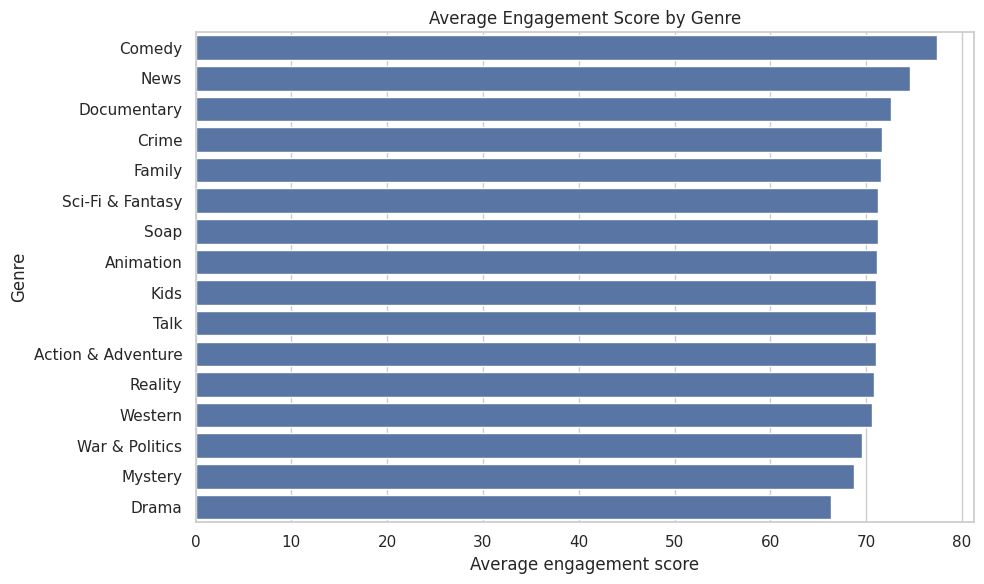

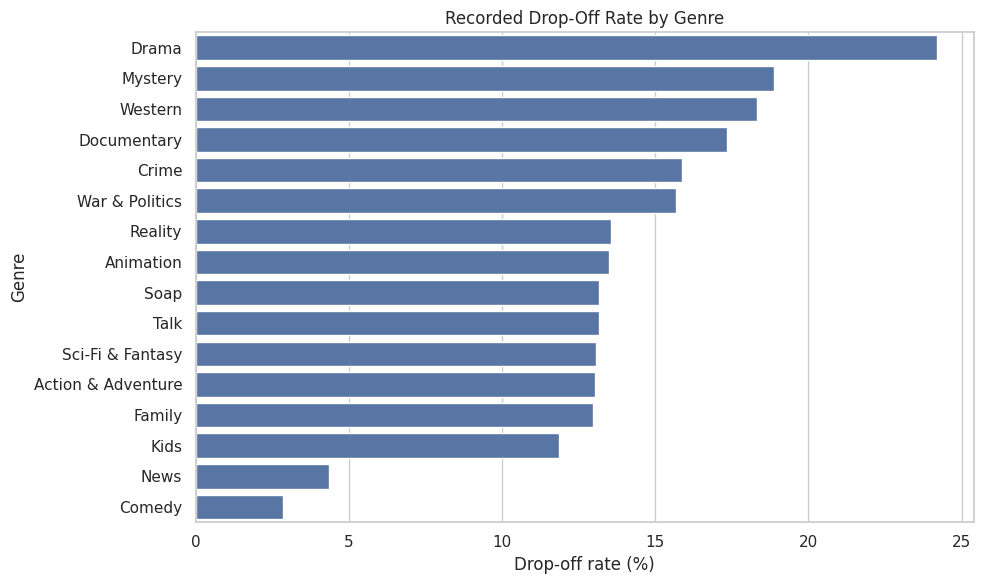

Export step finished. Check the outputs/ and images/ folders in the Colab Files panel.


In [ ]:
# Save useful summary tables and selected charts for the project repository.
os.makedirs("outputs", exist_ok=True)
os.makedirs("images", exist_ok=True)

tables_to_save = {
    "genre_engagement": globals().get("genre_engagement"),
    "genre_watch": globals().get("genre_watch"),
    "genre_dropoff": globals().get("genre_dropoff"),
    "episode_dropoff": globals().get("episode_dropoff"),
    "season_summary": globals().get("season_summary"),
    "risk_summary": globals().get("risk_summary"),
    "intro_summary": globals().get("intro_summary"),
}

for name, table in tables_to_save.items():
    if isinstance(table, pd.DataFrame):
        table.to_csv(f"outputs/{name}.csv", index=True)

# Export the ranked episode lists when engagement score is available.
if "engagement_score" in df:
    export_cols = [c for c in [
        "title", "platform", "genre", "season_number", "episode_number",
        "avg_watch_percentage", "engagement_score", "drop_off_probability",
        "retention_risk"
    ] if c in df]
    df.nlargest(10, "engagement_score")[export_cols].to_csv(
        "outputs/top_10_episodes.csv", index=False
    )
    df.nsmallest(10, "engagement_score")[export_cols].to_csv(
        "outputs/bottom_10_episodes.csv", index=False
    )

# Save two simple, reusable charts if the summary tables exist.
if "genre_engagement" in globals() and not genre_engagement.empty:
    fig, ax = plt.subplots(figsize=(10, 6))
    sns.barplot(data=genre_engagement.reset_index(), x="average_engagement", y="genre", ax=ax)
    ax.set_title("Average Engagement Score by Genre")
    ax.set_xlabel("Average engagement score")
    ax.set_ylabel("Genre")
    fig.tight_layout()
    fig.savefig("images/engagement_by_genre.png", dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)

if "genre_dropoff" in globals() and not genre_dropoff.empty:
    plot_data = genre_dropoff.reset_index()
    rate_col = "drop_off_rate_pct" if "drop_off_rate_pct" in plot_data else "drop_off_rate"
    fig, ax = plt.subplots(figsize=(10, 6))
    sns.barplot(data=plot_data, x=rate_col, y="genre", ax=ax)
    ax.set_title("Recorded Drop-Off Rate by Genre")
    ax.set_xlabel("Drop-off rate (%)" if rate_col.endswith("_pct") else "Drop-off rate")
    ax.set_ylabel("Genre")
    fig.tight_layout()
    fig.savefig("images/dropoff_by_genre.png", dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)

print("Export step finished. Check the outputs/ and images/ folders in the Colab Files panel.")

# **Export Results**

In [ ]:

# Generate and export project charts, tables, and datasets

import os
import shutil
import zipfile
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files

EXPORT_DIR = "/content/ott_project_exports"
CHART_DIR = os.path.join(EXPORT_DIR, "charts")
TABLE_DIR = os.path.join(EXPORT_DIR, "tables")
DATA_DIR = os.path.join(EXPORT_DIR, "data")
ZIP_PATH = "/content/OTT_Viewer_Engagement_Project_Results.zip"

# Start with clean export folders
if os.path.exists(EXPORT_DIR):
    shutil.rmtree(EXPORT_DIR)

for folder in [CHART_DIR, TABLE_DIR, DATA_DIR]:
    os.makedirs(folder, exist_ok=True)

chart_count = 0
table_count = 0

def safe_filename(name):
    return re.sub(r"[^a-zA-Z0-9_-]+", "_", name).strip("_")

# Existing analysis tables from the notebook
table_names = [
    "genre_engagement",
    "genre_watch",
    "genre_dropoff",
    "episode_dropoff",
    "risk_summary",
    "hook_summary",
    "pacing_summary",
    "cognitive_summary",
    "intro_summary",
    "season_summary",
    "show_summary",
    "high_risk_shows",
    "review",
    "table",
    "plot_data",
]

# Export datasets and analysis tables
for name in ["df_raw", "df"] + table_names:
    obj = globals().get(name)

    if isinstance(obj, pd.DataFrame) and not obj.empty:
        folder = DATA_DIR if name in ["df_raw", "df"] else TABLE_DIR
        obj.to_csv(
            os.path.join(folder, f"{safe_filename(name)}.csv"),
            index=False
        )
        table_count += 1

# Generate charts from each available summary table
for name in table_names:
    data = globals().get(name)

    if not isinstance(data, pd.DataFrame) or data.empty:
        continue

    numeric_cols = data.select_dtypes(include="number").columns.tolist()
    categorical_cols = [
        col for col in data.columns
        if col not in numeric_cols
    ]

    if not numeric_cols:
        continue

    # Choose a meaningful metric when possible
    preferred = [
        col for col in numeric_cols
        if any(word in str(col).lower() for word in [
            "drop", "watch", "engage", "risk", "score",
            "percent", "retention", "rewind", "pause",
            "hook", "pacing", "load", "rate"
        ])
    ]
    metric = preferred[0] if preferred else numeric_cols[-1]

    plot_df = data.copy()

    # Choose a category for the x-axis
    if categorical_cols:
        category = categorical_cols[0]
        plot_df = plot_df[[category, metric]].dropna()
        plot_df[category] = plot_df[category].astype(str)

        # Limit large tables to a readable top 15
        if len(plot_df) > 15:
            plot_df = plot_df.nlargest(15, metric)

        plot_df = plot_df.sort_values(metric, ascending=False)

        fig, ax = plt.subplots(figsize=(11, 6))
        ax.bar(plot_df[category], plot_df[metric])
        ax.set_xlabel(category.replace("_", " ").title())
        ax.set_ylabel(metric.replace("_", " ").title())
        ax.set_title(f"{name.replace('_', ' ').title()}")
        ax.tick_params(axis="x", rotation=45)
        fig.tight_layout()

    else:
        # Numeric-only tables: plot their values
        values = data[metric].dropna()

        if len(values) < 2:
            continue

        fig, ax = plt.subplots(figsize=(9, 5))
        ax.plot(range(len(values)), values, marker="o")
        ax.set_xlabel("Index")
        ax.set_ylabel(metric.replace("_", " ").title())
        ax.set_title(f"{name.replace('_', ' ').title()}")
        fig.tight_layout()

    filename = f"{safe_filename(name)}.png"
    fig.savefig(
        os.path.join(CHART_DIR, filename),
        dpi=200,
        bbox_inches="tight"
    )
    plt.close(fig)
    chart_count += 1

# Correlation heatmap
if isinstance(globals().get("corr_matrix"), pd.DataFrame):
    corr = corr_matrix.select_dtypes(include="number")

    if not corr.empty:
        fig, ax = plt.subplots(figsize=(12, 9))
        image = ax.imshow(corr.values, cmap="coolwarm", vmin=-1, vmax=1)
        ax.set_xticks(range(len(corr.columns)))
        ax.set_yticks(range(len(corr.index)))
        ax.set_xticklabels(corr.columns, rotation=90, fontsize=8)
        ax.set_yticklabels(corr.index, fontsize=8)
        ax.set_title("Feature Correlation Heatmap")
        fig.colorbar(image, ax=ax, label="Correlation")
        fig.tight_layout()
        fig.savefig(
            os.path.join(CHART_DIR, "correlation_heatmap.png"),
            dpi=200,
            bbox_inches="tight"
        )
        plt.close(fig)
        chart_count += 1

# Save a short export report
with open(
    os.path.join(EXPORT_DIR, "project_summary.txt"),
    "w",
    encoding="utf-8"
) as report:
    report.write("OTT Viewer Engagement & Retention Risk Analysis\n")
    report.write("=" * 50 + "\n\n")
    report.write(f"Rows in cleaned dataset: {len(df)}\n")
    report.write(f"Columns in cleaned dataset: {len(df.columns)}\n")
    report.write(f"Exported tables/data files: {table_count}\n")
    report.write(f"Generated charts: {chart_count}\n\n")
    report.write("Chart values are generated from the notebook's current DataFrames.\n")
    report.write("Review the chart labels and metrics before interpreting results.\n")

# Create ZIP
if os.path.exists(ZIP_PATH):
    os.remove(ZIP_PATH)

with zipfile.ZipFile(ZIP_PATH, "w", zipfile.ZIP_DEFLATED) as archive:
    for root, _, filenames in os.walk(EXPORT_DIR):
        for filename in filenames:
            path = os.path.join(root, filename)
            archive.write(path, os.path.relpath(path, EXPORT_DIR))

print("Export completed!")
print("Tables/data files:", table_count)
print("Charts generated:", chart_count)
print("ZIP size:", round(os.path.getsize(ZIP_PATH) / (1024 * 1024), 2), "MB")
print("Chart folder:", CHART_DIR)

files.download(ZIP_PATH)


Export completed!
Tables/data files: 17
Charts generated: 15
ZIP size: 2.05 MB
Chart folder: /content/ott_project_exports/charts


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>